# Day 30 | Choose a Document Converter

**KGP Talkie**

Compare simple Markdown conversion with layout-aware document reading.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

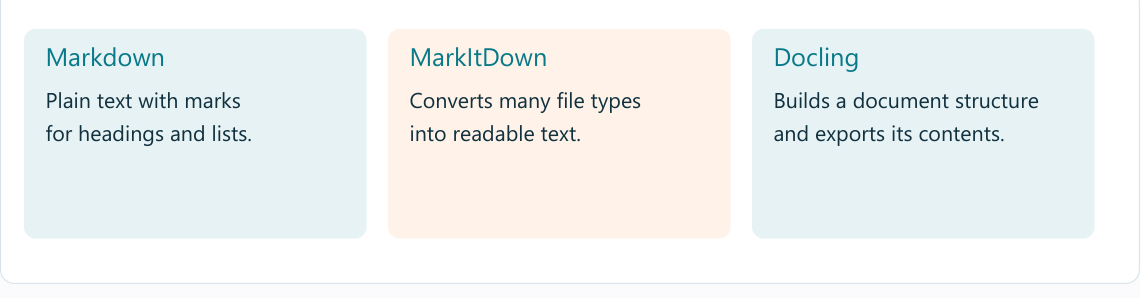

MarkItDown converts a supported file into text. This HTML input does not need audio or OCR extras.

In [5]:
from markitdown import MarkItDown

In [6]:
simple = MarkItDown().convert(str(ASSETS / "workshop.html"))

In [7]:
print(simple.text_content)

Home Login

# Workshop

Python starts at 10:00.

Pandas starts at 11:00.

| Class | Room |
| --- | --- |
| Python | 2 |
| Pandas | 3 |

Subscribe


Docling returns a document structure. We use its HTML pipeline so no OCR weights are downloaded for this exercise.

In [8]:
from docling.document_converter import DocumentConverter

In [9]:
from docling.datamodel.base_models import InputFormat

Restrict this converter to the one file type we are teaching here.

In [10]:
converter = DocumentConverter(allowed_formats=[InputFormat.HTML])

In [11]:
converted = converter.convert(str(ASSETS / "workshop.html"))

In [12]:
markdown = converted.document.export_to_markdown()
print(markdown)

# Workshop

Python starts at 10:00.

Pandas starts at 11:00.

| Class   |   Room |
|---------|--------|
| Python  |      2 |
| Pandas  |      3 |


Save a new output file. The original HTML stays available for comparison.

In [13]:
(OUTPUT / "workshop.md").write_text(markdown, encoding="utf-8")

145

In [14]:
print("Has Python:", "Python" in markdown)
print("Has Room:", "Room" in markdown)

Has Python: True
Has Room: True


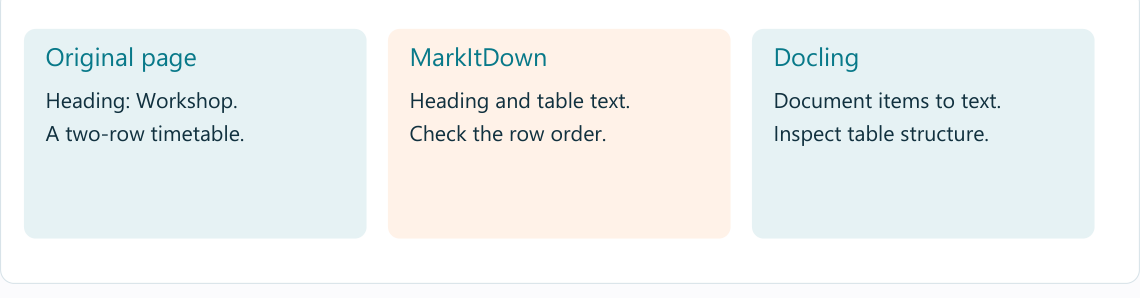

## Try a fresh input

Write the Markdown to a new file. Keep the original so we can check what changed.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-document-loaders).